# Método CASTLE · Notebook 1: Captura y Alfa
**Castle Quant** — De los datos crudos de mercado a un modelo predictivo en PyTorch.

## C · Captura y A · Alfa
En este notebook capturamos las velas de 1 minuto del contrato perpetuo **BTCUSDT** y construimos un modelo autorregresivo lineal que predice su **retorno logarítmico futuro (`close_log_return`)**.

In [1]:
# Arquitectura conceptual de un sistema cuantitativo:
# y_hat = model(x)         -> 1. Predicción del retorno futuro (Modelo)
# orders = strategy(y_hat) -> 2. Generación de señales y tamaño de posición (Estrategia)
# execute(orders)          -> 3. Envío y gestión de órdenes en el mercado (Ejecución)

In [2]:
# Método CASTLE:
# C · Captura + A · Alfa                           -> y_hat = model(x)           (este notebook)
# S · Simulación + T · Tamaño + L · Libre de sesgos -> orders = strategy(y_hat)   (notebook 2)
# E · Ejecución                                    -> execute(orders)            (notebook 3)

### Configuración del Entorno y Parámetros Base

In [3]:
# Solo en Google Colab: trae las librerías del método (research.py, binance.py, models.py)
import os, sys
if 'google.colab' in sys.modules and not os.path.exists('research.py'):
    !git clone --depth 1 https://github.com/JuliRey2000/metodo_CASTLE_castlequant.com.git
    %cd metodo_CASTLE_castlequant.com

In [4]:
# Librerías de datos y análisis numérico
import polars as pl                         # DataFrames de alto rendimiento para series financieras
import numpy as np                          # Cálculo numérico y matricial
from datetime import datetime               # Manejo de fechas

# Librerías de Machine Learning
import torch                                # Framework PyTorch
import torch.nn as nn                       # Módulos de redes neuronales y capas
import torch.optim as optim                 # Algoritmos de optimización (Adam, SGD, etc.)
import research                             # Utilidades propias de investigación, métricas y entrenamiento

# Fuentes de datos
import binance                              # Descarga y caché de velas de 1 minuto de Binance Futures

In [5]:
# Fijamos la semilla global (random, numpy, torch) para garantizar reproducibilidad exacta
research.set_seed(42)

In [6]:
# Configuración de visualización de tablas en Polars
pl.Config.set_tbl_width_chars(200)
pl.Config.set_fmt_str_lengths(100)
pl.Config.set_tbl_cols(-1);  # Mostrar todas las columnas sin truncar

In [7]:
# Símbolo del par perpetuo a operar
sym = 'BTCUSDT'
# Intervalo temporal de agregación de las velas (Timeframe inicial)
time_interval = '1h'
# Número máximo de rezagos (lags) autorregresivos a explorar
max_lags = 4
# Horizonte de predicción en pasos hacia adelante (1 paso = 1 vela)
forecast_horizon = 1
# Factor de anualización del Sharpe Ratio (cripto opera 365 días, 24h al día)
annualized_rate = research.sharpe_annualization_factor(time_interval, 365, 24)

---
# C · Captura
### Descarga y Agregación de Datos (Binance Futures)

In [8]:
# Descarga de las velas de 1 minuto desde Binance Vision (se guardan en ./cache como archivos .parquet)
# Fijamos el rango exacto de fechas para reproducir los mismos resultados del estudio
start_date = datetime(2022, 1, 1)
end_date = datetime(2026, 10, 31)
binance.download_date_range(sym, start_date, end_date)

In [9]:
# El dato crudo: una fila por minuto, con precios, volumen, número de trades y cuánto fue compra a mercado
binance.load_klines(sym, start_date, end_date)

datetime,open,high,low,close,volume,quote_volume,n_trades,buy_volume,buy_quote_volume
datetime[μs],f64,f64,f64,f64,f64,f64,i64,f64,f64
2022-01-01 00:00:00,46210.57,46265.41,46210.55,46246.66,253.757,1.1735e7,1921,117.288,5.4231e6
2022-01-01 00:01:00,46246.66,46335.17,46235.8,46314.36,275.296,1.2742e7,2040,211.014,9.7664e6
2022-01-01 00:02:00,46311.81,46385.4,46283.01,46367.54,304.721,1.4121e7,2772,178.903,8.2906e6
2022-01-01 00:03:00,46367.54,46390.83,46305.61,46328.0,182.41,8.4552e6,1773,72.691,3.3696e6
2022-01-01 00:04:00,46327.99,46332.59,46292.18,46316.17,64.906,3.0062e6,1007,28.649,1.3268e6
…,…,…,…,…,…,…,…,…,…
2026-10-31 23:55:00,77507.3,77507.3,77507.2,77507.3,3.503,271507.889,168,1.674,129747.2202
2026-10-31 23:56:00,77507.3,77507.3,77507.2,77507.2,2.165,167803.2655,139,1.775,137575.4575
2026-10-31 23:57:00,77507.2,77507.3,77507.2,77507.2,5.543,429622.8256,181,4.16,322430.368


In [10]:
# Agregamos las velas de 1 minuto en barras OHLC (Open, High, Low, Close) al intervalo definido ('1h')
ts = research.load_ohlc_timeseries_range(sym, time_interval, start_date, end_date)
ts

datetime,open,high,low,close
datetime[μs],f64,f64,f64,f64
2022-01-01 00:00:00,46210.57,46729.73,46210.55,46650.01
2022-01-01 01:00:00,46650.0,46944.56,46570.34,46766.78
2022-01-01 02:00:00,46767.44,46917.87,46709.44,46796.14
2022-01-01 03:00:00,46796.15,46888.0,46746.32,46789.56
2022-01-01 04:00:00,46789.55,46868.74,46605.0,46690.81
…,…,…,…,…
2026-10-31 19:00:00,77582.9,77643.0,77510.5,77540.0
2026-10-31 20:00:00,77539.9,77593.0,77514.9,77521.6
2026-10-31 21:00:00,77521.7,77635.1,77395.8,77633.1


In [11]:
# Ejemplo de agregación personalizada desde el dato crudo: volumen negociado y fracción de compras a mercado por hora
research.load_timeseries_range(sym, time_interval, start_date, end_date, [
    pl.col('quote_volume').sum(),
    (pl.col('buy_quote_volume').sum() / pl.col('quote_volume').sum()).alias('buy_ratio'),
])

datetime,quote_volume,buy_ratio
datetime[μs],f64,f64
2022-01-01 00:00:00,4.1644e8,0.533395
2022-01-01 01:00:00,3.4038e8,0.507135
2022-01-01 02:00:00,2.0969e8,0.469689
2022-01-01 03:00:00,1.9708e8,0.45811
2022-01-01 04:00:00,2.8723e8,0.464456
…,…,…
2026-10-31 19:00:00,5.9323e7,0.505701
2026-10-31 20:00:00,4.0337e7,0.55898
2026-10-31 21:00:00,1.8514e8,0.507712


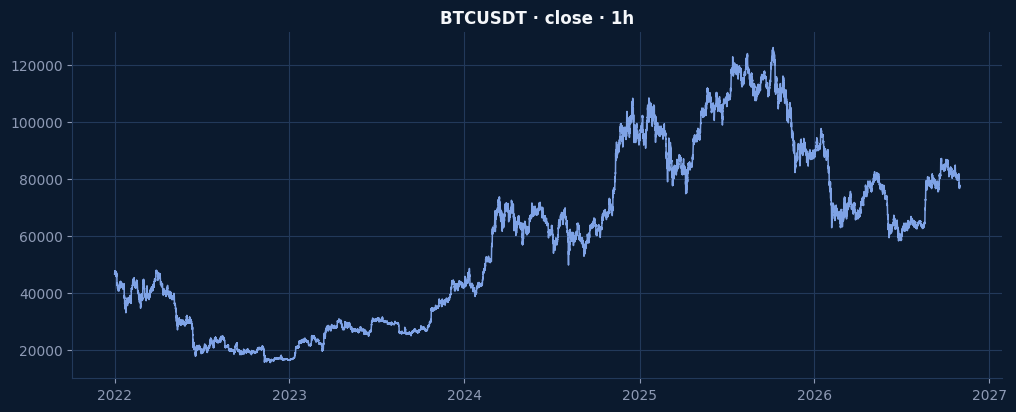

In [12]:
# Serie de precios de cierre
research.plot_static_timeseries(ts, sym, 'close', time_interval)

---
# A · Alfa
### Ingeniería de Variables (Feature Engineering)
Los precios brutos no son estacionarios. Comparamos tres formas de medir el cambio de precio: diferencia absoluta (`delta`), retorno simple (`return`) y **retorno logarítmico (`log_return`)**:
$$r_t = \ln\left(\frac{P_t}{P_{t-1}}\right)$$
El retorno logarítmico es **simétrico** (subir de 100 a 120 y bajar de 120 a 100 suma exactamente 0) y **aditivo en el tiempo**.

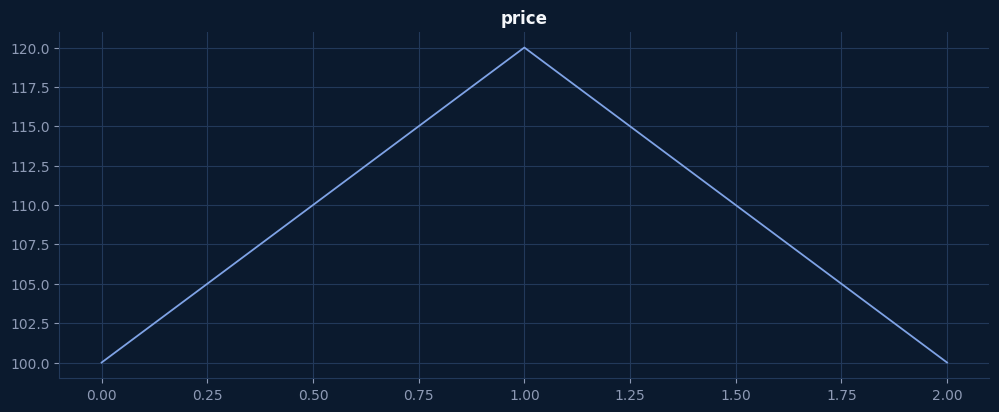

In [13]:
# Ejemplo sintético: el precio sube de 100 a 120 (+20%) y vuelve a bajar a 100 (-16.67%)
price_time_series = pl.DataFrame({'price':[100.0,120.0,100.0]})
research.plot_column(price_time_series, 'price')

In [14]:
# Comparación entre diferencia absoluta, retorno porcentual simple y retorno logarítmico
price_time_series.with_columns(
    pl.col('price').diff().alias('delta'),
    ((pl.col('price')-pl.col('price').shift())/pl.col('price').shift()).alias('return'),
    (pl.col('price')/pl.col('price').shift()).log().alias('log_return'),
)

price,delta,return,log_return
f64,f64,f64,f64
100.0,null,null,null
120.0,20.0,0.2,0.182322
100.0,-20.0,-0.166667,-0.182322


### Creación del Target y Variables Rezagadas (Lags Autorregresivos)
Construimos la variable objetivo (`close_log_return`) y sus rezagos pasados (`lag_1` a `lag_4`) para usarlos como predictores sin incurrir en *look-ahead bias*.

In [15]:
# Calculamos el retorno logarítmico del cierre respecto a 'forecast_horizon' periodos atrás
ts = ts.with_columns((pl.col('close')/pl.col('close').shift(forecast_horizon)).log().alias('close_log_return'))
ts

datetime,open,high,low,close,close_log_return
datetime[μs],f64,f64,f64,f64,f64
2022-01-01 00:00:00,46210.57,46729.73,46210.55,46650.01,null
2022-01-01 01:00:00,46650.0,46944.56,46570.34,46766.78,0.0025
2022-01-01 02:00:00,46767.44,46917.87,46709.44,46796.14,0.000628
2022-01-01 03:00:00,46796.15,46888.0,46746.32,46789.56,-0.000141
2022-01-01 04:00:00,46789.55,46868.74,46605.0,46690.81,-0.002113
…,…,…,…,…,…
2026-10-31 19:00:00,77582.9,77643.0,77510.5,77540.0,-0.000553
2026-10-31 20:00:00,77539.9,77593.0,77514.9,77521.6,-0.000237
2026-10-31 21:00:00,77521.7,77635.1,77395.8,77633.1,0.001437


In [16]:
# Construcción explícita de los rezagos (lags) desplazando la serie hacia adelante con .shift()
target = 'close_log_return'
lr = pl.col(target)
ts = ts.with_columns(
    lr.shift(forecast_horizon * 1).alias(f'{target}_lag_1'),
    lr.shift(forecast_horizon * 2).alias(f'{target}_lag_2'),
    lr.shift(forecast_horizon * 3).alias(f'{target}_lag_3'),
    lr.shift(forecast_horizon * 4).alias(f'{target}_lag_4'),
)
ts

datetime,open,high,low,close,close_log_return,close_log_return_lag_1,close_log_return_lag_2,close_log_return_lag_3,close_log_return_lag_4
datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64
2022-01-01 00:00:00,46210.57,46729.73,46210.55,46650.01,null,null,null,null,null
2022-01-01 01:00:00,46650.0,46944.56,46570.34,46766.78,0.0025,null,null,null,null
2022-01-01 02:00:00,46767.44,46917.87,46709.44,46796.14,0.000628,0.0025,null,null,null
2022-01-01 03:00:00,46796.15,46888.0,46746.32,46789.56,-0.000141,0.000628,0.0025,null,null
2022-01-01 04:00:00,46789.55,46868.74,46605.0,46690.81,-0.002113,-0.000141,0.000628,0.0025,null
…,…,…,…,…,…,…,…,…,…
2026-10-31 19:00:00,77582.9,77643.0,77510.5,77540.0,-0.000553,-0.001051,0.001219,0.000126,0.002291
2026-10-31 20:00:00,77539.9,77593.0,77514.9,77521.6,-0.000237,-0.000553,-0.001051,0.001219,0.000126
2026-10-31 21:00:00,77521.7,77635.1,77395.8,77633.1,0.001437,-0.000237,-0.000553,-0.001051,0.001219


In [17]:
# Función auxiliar equivalente en research.py para generar 'max_lags' rezagos automáticamente
ts = research.add_lags(ts, target, max_lags, forecast_horizon)
ts

datetime,open,high,low,close,close_log_return,close_log_return_lag_1,close_log_return_lag_2,close_log_return_lag_3,close_log_return_lag_4
datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64
2022-01-01 00:00:00,46210.57,46729.73,46210.55,46650.01,null,null,null,null,null
2022-01-01 01:00:00,46650.0,46944.56,46570.34,46766.78,0.0025,null,null,null,null
2022-01-01 02:00:00,46767.44,46917.87,46709.44,46796.14,0.000628,0.0025,null,null,null
2022-01-01 03:00:00,46796.15,46888.0,46746.32,46789.56,-0.000141,0.000628,0.0025,null,null
2022-01-01 04:00:00,46789.55,46868.74,46605.0,46690.81,-0.002113,-0.000141,0.000628,0.0025,null
…,…,…,…,…,…,…,…,…,…
2026-10-31 19:00:00,77582.9,77643.0,77510.5,77540.0,-0.000553,-0.001051,0.001219,0.000126,0.002291
2026-10-31 20:00:00,77539.9,77593.0,77514.9,77521.6,-0.000237,-0.000553,-0.001051,0.001219,0.000126
2026-10-31 21:00:00,77521.7,77635.1,77395.8,77633.1,0.001437,-0.000237,-0.000553,-0.001051,0.001219


In [18]:
# Eliminamos las primeras filas con valores nulos originados por el desplazamiento (.shift)
ts = ts.drop_nulls()

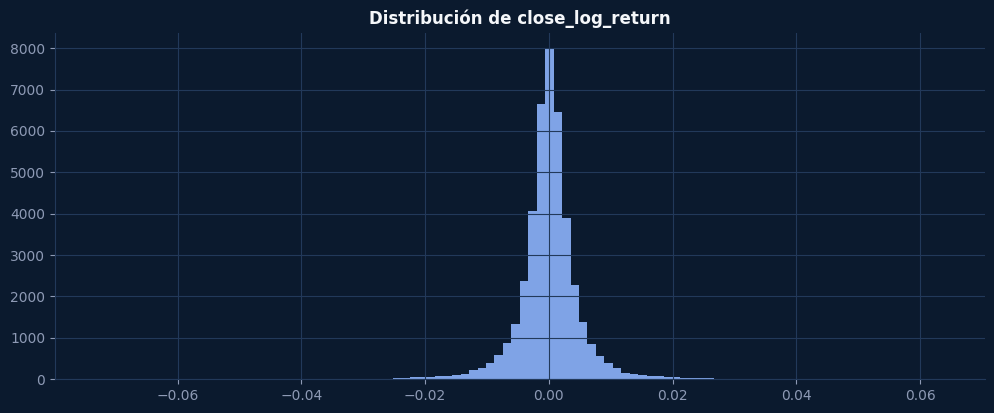

In [19]:
# Distribución del retorno logarítmico: centrada en 0, estacionaria y con colas pesadas (leptocúrtica)
research.plot_distribution(ts, target, no_bins = 100)

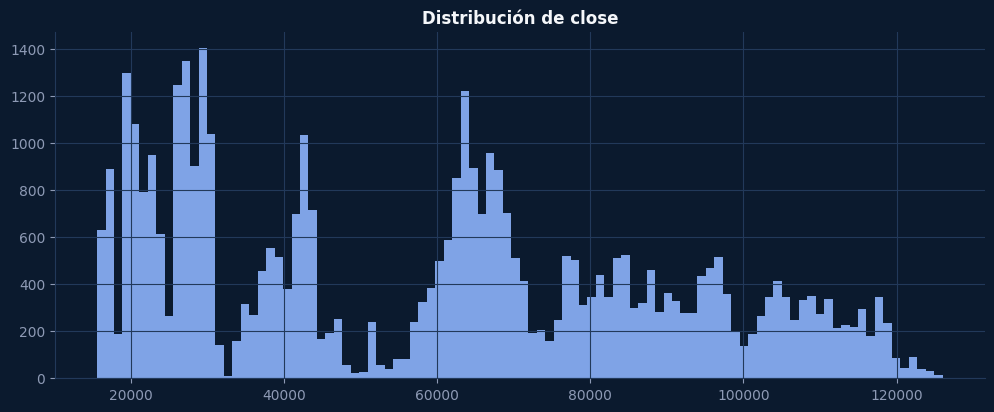

In [20]:
# En contraste, la distribución del precio de cierre ('close') es multimodal y no estacionaria
research.plot_distribution(ts, 'close', no_bins = 100)

### Construcción del Modelo en PyTorch
Definimos una regresión lineal $\hat{y} = w \cdot x + b$. En finanzas cuantitativas con baja relación señal/ruido, los modelos lineales ofrecen alta interpretabilidad y menor riesgo de sobreajuste (*overfitting*).

In [21]:
class LinearModel(nn.Module):
    def __init__(self, input_features):
        super(LinearModel, self).__init__()
        self.linear = nn.Linear(input_features, 1)  # Capa lineal: entradas -> 1 predicción continua

    def forward(self, x):
        return self.linear(x)

### Complejidad del Modelo
Con 1 sola variable de entrada (`input_features = 1`), el modelo únicamente aprende 2 parámetros: el peso ($w$) y el sesgo ($b$).

In [22]:
input_features = 1

linear_model = LinearModel(input_features)

research.print_model_info(linear_model, "Linear Model")


Linear Model

Architecture:
  LinearModel(
  (linear): Linear(in_features=1, out_features=1, bias=True)
)

Parameter Count:
  Total parameters:      2



### División Temporal (Entrenamiento / Validación / Prueba)
En series de tiempo financieras **nunca** se mezclan los datos aleatoriamente. Dividimos respetando el orden cronológico: el primer 60% para **entrenamiento** (se estiman los pesos), el siguiente 20% para **validación** (se elige el modelo) y el último 20% para **prueba**, que queda sellada hasta el notebook 2.

In [23]:
features = ['close_log_return_lag_1']
target = 'close_log_return'
val_size = 0.2
test_size = 0.2

In [24]:
# Total de observaciones disponibles
len(ts)

42355

In [25]:
# Índices exactos de corte temporal (60% y 80%)
val_idx = int(len(ts) * (1 - val_size - test_size))
test_idx = int(len(ts) * (1 - test_size))
val_idx, test_idx

(25413, 33884)

In [26]:
# Partición cronológica del DataFrame. Lo que hay después de test_idx no se mira en este notebook
ts_train, ts_val = ts[:val_idx], ts[val_idx:test_idx]

In [27]:
ts_train

datetime,open,high,low,close,close_log_return,close_log_return_lag_1,close_log_return_lag_2,close_log_return_lag_3,close_log_return_lag_4
datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64
2022-01-01 05:00:00,46690.81,47566.66,46657.99,47184.18,0.010511,-0.002113,-0.000141,0.000628,0.0025
2022-01-01 06:00:00,47184.19,47314.4,46914.84,46972.19,-0.004503,0.010511,-0.002113,-0.000141,0.000628
2022-01-01 07:00:00,46972.19,47247.44,46867.0,47186.83,0.004559,-0.004503,0.010511,-0.002113,-0.000141
2022-01-01 08:00:00,47186.83,47338.0,47060.74,47117.84,-0.001463,0.004559,-0.004503,0.010511,-0.002113
2022-01-01 09:00:00,47118.78,47200.0,46920.02,47137.37,0.000414,-0.001463,0.004559,-0.004503,0.010511
…,…,…,…,…,…,…,…,…,…
2024-11-24 21:00:00,96888.0,97061.4,96645.3,97037.7,0.001544,0.005083,-0.002165,0.006365,-0.005268
2024-11-24 22:00:00,97037.7,98086.3,97037.7,98082.0,0.010704,0.001544,0.005083,-0.002165,0.006365
2024-11-24 23:00:00,98082.1,98429.7,97577.7,97960.4,-0.001241,0.010704,0.001544,0.005083,-0.002165


In [28]:
ts_val

datetime,open,high,low,close,close_log_return,close_log_return_lag_1,close_log_return_lag_2,close_log_return_lag_3,close_log_return_lag_4
datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-11-25 02:00:00,97257.2,97782.0,97254.4,97414.3,0.001614,-0.005189,-0.002015,-0.001241,0.010704
2024-11-25 03:00:00,97414.3,97947.0,97384.6,97935.9,0.00534,0.001614,-0.005189,-0.002015,-0.001241
2024-11-25 04:00:00,97935.8,98100.0,97600.0,97859.3,-0.000782,0.00534,0.001614,-0.005189,-0.002015
2024-11-25 05:00:00,97859.3,98300.0,97828.5,98131.4,0.002777,-0.000782,0.00534,0.001614,-0.005189
2024-11-25 06:00:00,98131.4,98421.6,98083.0,98131.8,0.000004,0.002777,-0.000782,0.00534,0.001614
…,…,…,…,…,…,…,…,…,…
2025-11-12 20:00:00,101245.3,101795.3,101087.8,101494.9,0.002461,-0.002448,-0.002032,0.003022,-0.007192
2025-11-12 21:00:00,101494.9,101880.1,101467.1,101880.1,0.003788,0.002461,-0.002448,-0.002032,0.003022
2025-11-12 22:00:00,101880.0,101951.0,101400.0,101922.6,0.000417,0.003788,0.002461,-0.002448,-0.002032


In [29]:
# Conversión de DataFrames de Polars a tensores de PyTorch en precisión float32
X_train = torch.tensor(ts_train[features].to_numpy(), dtype=torch.float32)
X_val = torch.tensor(ts_val[features].to_numpy(), dtype=torch.float32)
y_train = torch.tensor(ts_train[target].to_numpy(), dtype=torch.float32)
y_val = torch.tensor(ts_val[target].to_numpy(), dtype=torch.float32)

In [30]:
X_train

tensor([[-0.0021],
        [ 0.0105],
        [-0.0045],
        ...,
        [ 0.0107],
        [-0.0012],
        [-0.0020]])

In [31]:
X_train.shape

torch.Size([25413, 1])

In [32]:
y_train.shape

torch.Size([25413])

In [33]:
# Redimensionamos el vector objetivo a matriz columna (N, 1) para que coincida con la salida de nn.Linear
y_train = y_train.reshape(-1, 1)
y_val = y_val.reshape(-1, 1)
y_train.shape

torch.Size([25413, 1])

In [34]:
# Función auxiliar en research.py que automatiza todo el proceso de división temporal y conversión a tensores
X_train, X_val, y_train, y_val = research.timeseries_train_val_split(ts, features, target, val_size, test_size)

### Entrenamiento por Descenso de Gradiente (Batch Gradient Descent)
Entrenamos el modelo minimizando el Error Cuadrático Medio (`MSELoss`) mediante el optimizador `Adam` y evaluamos la pérdida fuera del entrenamiento (*Validation Loss*).

In [35]:
# Hiperparámetros de entrenamiento
no_epochs = 1000 * 5
lr = 0.001

# Instanciar el modelo
model = LinearModel(len(features))
# Función de pérdida (MSE)
criterion = nn.MSELoss()
# Optimizador Adam
optimizer = optim.Adam(model.parameters(), lr = lr)

print("\nTraining model...")

for epoch in range(no_epochs):
    # 1. Forward pass (predicción)
    y_hat = model(X_train)
    loss = criterion(y_hat, y_train)

    # 2. Backward pass (retropropagación)
    optimizer.zero_grad()   # Limpiar gradientes acumulados del paso anterior
    loss.backward()         # Calcular gradientes respecto a la pérdida actual
    optimizer.step()        # Actualizar pesos y sesgo

    # Guardar valor escalar de pérdida
    train_loss = loss.item()

    # Registro de progreso cada 500 épocas
    if (epoch + 1) % 500 == 0:
        print(f"Epoch [{epoch+1}/{no_epochs}], Loss: {train_loss:.6f}")

print("\nLearned parameters")

for name, param in model.named_parameters():
    if param.requires_grad:
        print(f"{name}:\n{param.data.numpy()}")

# Evaluación en el conjunto de validación (sin cálculo de gradientes)
model.eval()
with torch.no_grad():
    y_hat = model(X_val)
    val_loss = criterion(y_hat, y_val)
    print(f"\nValidation Loss: {val_loss.item():.6f}, Train Loss: {train_loss:.6f}")


Training model...
Epoch [500/5000], Loss: 0.235927
Epoch [1000/5000], Loss: 0.040798
Epoch [1500/5000], Loss: 0.003549


Epoch [2000/5000], Loss: 0.000153
Epoch [2500/5000], Loss: 0.000034
Epoch [3000/5000], Loss: 0.000033
Epoch [3500/5000], Loss: 0.000033


Epoch [4000/5000], Loss: 0.000033
Epoch [4500/5000], Loss: 0.000033
Epoch [5000/5000], Loss: 0.000033

Learned parameters
linear.weight:
[[-0.01027406]]
linear.bias:
[2.9173401e-05]

Validation Loss: 0.000023, Train Loss: 0.000033


In [36]:
# Comprobación: la fórmula cerrada de mínimos cuadrados (la de la sesión anterior) llega al mismo peso y al mismo sesgo
research.least_squares_params(X_train, y_train)

(array([-0.01027406]), 2.9173355183797616e-05)

### Evaluación del Desempeño Financiero (Backtest Vectorizado)
Una baja pérdida estadística no garantiza rentabilidad. Convertimos la predicción $\hat{y}$ en una señal direccional $\text{signal} = \text{sign}(\hat{y}) \in \{-1, +1\}$ y calculamos las métricas clave de trading sobre la validación.

In [37]:
# Construcción de la tabla de resultados de trading en el conjunto de validación
trade_results = pl.DataFrame({
    'y_hat': y_hat.squeeze().numpy(),
    'y': y_val.squeeze().numpy()
}).with_columns(
    (pl.col('y_hat').sign()==pl.col('y').sign()).alias('is_won'),  # ¿Acertó la dirección del movimiento?
    pl.col('y_hat').sign().alias('signal'),                        # +1 (Long) o -1 (Short)
).with_columns(
    (pl.col('signal') * pl.col('y')).alias('trade_log_return')     # Retorno logarítmico capturado por operación
).with_columns(
    pl.col('trade_log_return').cum_sum().alias('equity_curve')     # Curva de capital acumulada en escala log
)
trade_results

y_hat,y,is_won,signal,trade_log_return,equity_curve
f32,f32,bool,f32,f32,f32
0.000082,0.001614,true,1.0,0.001614,0.001614
0.000013,0.00534,true,1.0,0.00534,0.006954
-0.000026,-0.000782,true,-1.0,0.000782,0.007737
0.000037,0.002777,true,1.0,0.002777,0.010513
6.4578e-7,0.000004,true,1.0,0.000004,0.010517
…,…,…,…,…,…
0.000054,0.002461,true,1.0,0.002461,0.044191
0.000004,0.003788,true,1.0,0.003788,0.047979
-0.00001,0.000417,false,-1.0,-0.000417,0.047562


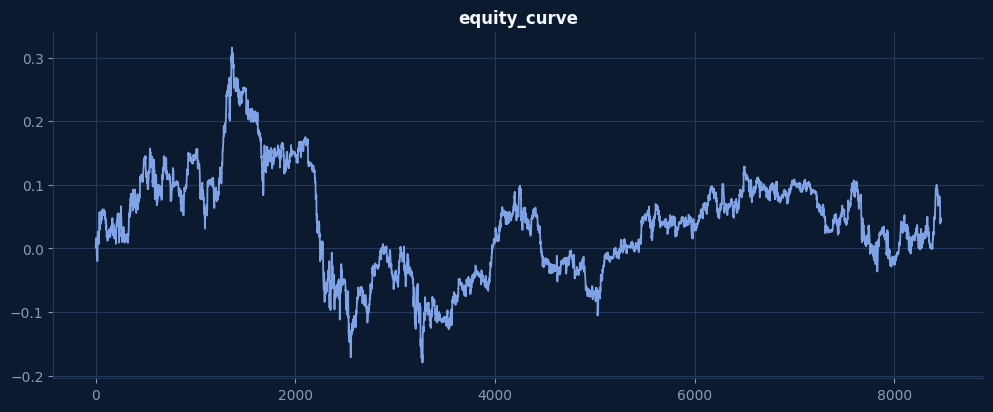

In [38]:
# Visualización de la curva de capital (Equity Curve bruta, antes de comisiones)
research.plot_column(trade_results, 'equity_curve')

In [39]:
# Cálculo del Drawdown en escala logarítmica: diferencia entre el capital actual y su máximo histórico previo
trade_results = trade_results.with_columns(
    (pl.col('equity_curve')-pl.col('equity_curve').cum_max()).alias('drawdown_log')
)
trade_results

y_hat,y,is_won,signal,trade_log_return,equity_curve,drawdown_log
f32,f32,bool,f32,f32,f32,f32
0.000082,0.001614,true,1.0,0.001614,0.001614,0.0
0.000013,0.00534,true,1.0,0.00534,0.006954,0.0
-0.000026,-0.000782,true,-1.0,0.000782,0.007737,0.0
0.000037,0.002777,true,1.0,0.002777,0.010513,0.0
6.4578e-7,0.000004,true,1.0,0.000004,0.010517,0.0
…,…,…,…,…,…,…
0.000054,0.002461,true,1.0,0.002461,0.044191,-0.271585
0.000004,0.003788,true,1.0,0.003788,0.047979,-0.267797
-0.00001,0.000417,false,-1.0,-0.000417,0.047562,-0.268214


In [40]:
# Máximo Drawdown en escala logarítmica
max_drawdown_log = trade_results['drawdown_log'].min()
max_drawdown_log

-0.49500608444213867

In [41]:
# Conversión del Max Drawdown logarítmico a porcentaje real: exp(dd_log) - 1
drawdown_pct = np.exp(max_drawdown_log) - 1
drawdown_pct

np.float64(-0.3904328015913223)

In [42]:
# Pérdida monetaria máxima desde un pico de $1,000 USD
equity_peak = 1000
equity_peak * drawdown_pct

np.float64(-390.43280159132235)

In [43]:
# Tasa de acierto (Win Rate): proporción de operaciones ganadoras
win_rate = trade_results['is_won'].mean()
win_rate

0.5072600637469012

In [44]:
# Valor Esperado (Expected Value - EV) por operación
avg_win = trade_results.filter(pl.col('is_won')==True)['trade_log_return'].mean()
avg_loss = trade_results.filter(pl.col('is_won')==False)['trade_log_return'].mean()
ev = win_rate * avg_win + (1 - win_rate) * avg_loss
ev

5.487775360005784e-06

In [45]:
# Retorno logarítmico total acumulado
total_log_return = trade_results['trade_log_return'].sum()
total_log_return

0.04648694768548012

In [46]:
# Factor de retorno compuesto real: exp(total_log_return)
compound_return = np.exp(total_log_return)
compound_return

np.float64(1.047584405578151)

In [47]:
# Capital final empezando con $1,000 USD (con reinversión compuesta)
1000*compound_return

np.float64(1047.5844055781508)

In [48]:
# Volatilidad (desviación estándar) de los retornos por operación
std = trade_results['trade_log_return'].std()
std

0.004800835158675909

In [49]:
# Sharpe Ratio anualizado: (Retorno medio por trade / Volatilidad por trade) * Factor de anualización
sharpe = ev / std * annualized_rate
sharpe

0.10698714151007739

In [50]:
# Función resumen en research.py que consolida todas las métricas de evaluación en un diccionario
research.eval_model_performance(y_val, y_hat, features, target, annualized_rate)

{'features': 'close_log_return_lag_1',
 'target': 'close_log_return',
 'no_trades': 8471,
 'win_rate': 0.5072600637469012,
 'avg_win': 0.0030785924964080655,
 'avg_loss': -0.0031581756137975207,
 'best_trade': 0.0497891828417778,
 'worst_trade': -0.050304364413022995,
 'ev': 5.4877753600053174e-06,
 'std': 0.004800835303684644,
 'total_log_return': 0.046486945074605046,
 'compound_return': 1.047584402843039,
 'max_drawdown': -0.49500630510533483,
 'equity_trough': -0.17923032053045063,
 'equity_peak': 0.3157759845748842,
 'sharpe': 0.10698713827853272}

In [51]:
# Búsqueda sistemática (Benchmark) sobre cada rezago individual usando pérdida L1 (MAE, más robusta a outliers)
feature_pool = [f'{target}_lag_{i}' for i in range(1, max_lags + 1)]
benchmark = research.benchmark_linear_models(ts, target, feature_pool, annualized_rate, loss=nn.L1Loss())
benchmark

features,target,no_trades,win_rate,avg_win,avg_loss,best_trade,worst_trade,ev,std,total_log_return,compound_return,max_drawdown,equity_trough,equity_peak,sharpe,weights,biases
str,str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str
"""close_log_return_lag_3""","""close_log_return""",8471,0.505135,0.003154,-0.003081,0.050304,-0.04697,0.000069,0.0048,0.581147,1.788089,-0.335383,-0.10856,0.81088,1.337615,"""[-0.01898]""","""5.7e-05"""
"""close_log_return_lag_2""","""close_log_return""",8471,0.513989,0.003062,-0.003177,0.050304,-0.049789,0.00003,0.004801,0.251412,1.28584,-0.511681,-0.266738,0.534645,0.578621,"""[-0.03021]""","""5.2e-05"""
"""close_log_return_lag_1""","""close_log_return""",8471,0.511274,0.003067,-0.003171,0.04697,-0.050304,0.000019,0.004801,0.158472,1.171719,-0.411426,-0.036603,0.378537,0.364717,"""[-0.09262]""","""5.9e-05"""
"""close_log_return_lag_4""","""close_log_return""",8471,0.496399,0.003091,-0.003144,0.050304,-0.049789,-0.000049,0.004801,-0.413486,0.661341,-0.669989,-0.419077,0.250912,-0.951663,"""[-0.01114]""","""6e-05"""


In [52]:
# Matriz de autocorrelación entre el retorno objetivo y sus rezagos (solo con el entrenamiento)
research.auto_reg_corr_matrx(ts_train, target, max_lags)

close_log_return,close_log_return_lag_1,close_log_return_lag_2,close_log_return_lag_3,close_log_return_lag_4
f64,f64,f64,f64,f64
1.0,-0.010274,-0.001586,-0.002692,-0.001755
-0.010274,1.0,-0.010286,-0.001595,-0.002632
-0.001586,-0.010286,1.0,-0.01029,-0.00157
-0.002692,-0.001595,-0.01029,1.0,-0.010272
-0.001755,-0.002632,-0.00157,-0.010272,1.0


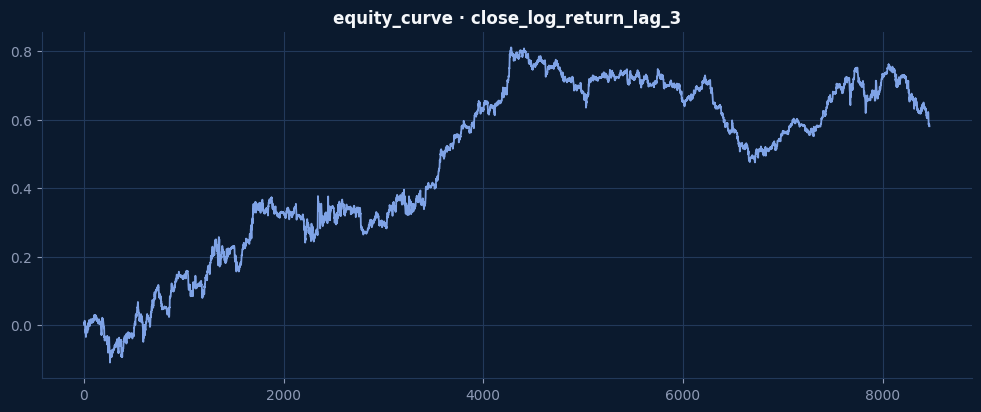

In [53]:
# Entrenamos y graficamos el mejor modelo univariado en 1h según la validación
features = benchmark['features'][0].split(',')
model = LinearModel(len(features))
model.apply(research.init_weights)
model_trades = research.learn_model_trades(ts, features, target, model, loss=nn.L1Loss())

research.plot_column(model_trades, 'equity_curve', f'equity_curve · {features[0]}')

## Impacto de las Comisiones de Transacción (Transaction Fees)
En la práctica, cada operación paga comisiones al exchange (*Maker* al proveer liquidez o *Taker* al tomar liquidez a mercado). Como primera aproximación suponemos el caso más exigente: entrar y salir en cada vela. Al operar cada hora (`1h`), la ventaja promedio por trade (`ev`) es mucho menor que el costo de comisión de entrada y salida (*roundtrip fee*).

In [54]:
# Comisiones de futuros perpetuos en Binance: Maker (0.02%) y Taker (0.05%)
maker_fee = binance.MAKER_FEE
taker_fee = binance.TAKER_FEE

# Costo logarítmico de abrir y cerrar una posición a mercado (2 operaciones Taker)
roundtrip_fee_log = np.log(1 - 2 * taker_fee)

model_trades = model_trades.with_columns(pl.lit(roundtrip_fee_log).alias('tx_fee_log'))
model_trades = model_trades.with_columns((pl.col('trade_log_return') + pl.col('tx_fee_log')).alias('trade_log_return_net'))
model_trades = model_trades.with_columns(pl.col('trade_log_return_net').cum_sum().alias('equity_curve_net'))

model_trades

y_pred,y_true,is_won,position,trade_log_return,equity_curve,drawdown_log_return,tx_fee_log,trade_log_return_net,equity_curve_net
f64,f64,bool,f64,f64,f64,f64,f64,f64,f64
0.000081,0.001614,true,1.0,0.001614,0.001614,0.0,-0.001001,0.000614,0.000614
0.000096,0.00534,true,1.0,0.00534,0.006954,0.0,-0.001001,0.00434,0.004953
0.000156,-0.000782,false,1.0,-0.000782,0.006172,-0.000782,-0.001001,-0.001783,0.00317
0.000027,0.002777,true,1.0,0.002777,0.008948,0.0,-0.001001,0.001776,0.004946
-0.000044,0.000004,false,-1.0,-0.000004,0.008944,-0.000004,-0.001001,-0.001005,0.003942
…,…,…,…,…,…,…,…,…,…
-6.8083e-8,0.002461,false,-1.0,-0.002461,0.582094,-0.228786,-0.001001,-0.003462,-7.889143
0.000096,0.003788,true,1.0,0.003788,0.585882,-0.224998,-0.001001,0.002788,-7.886355
0.000104,0.000417,true,1.0,0.000417,0.586299,-0.224581,-0.001001,-0.000583,-7.886939


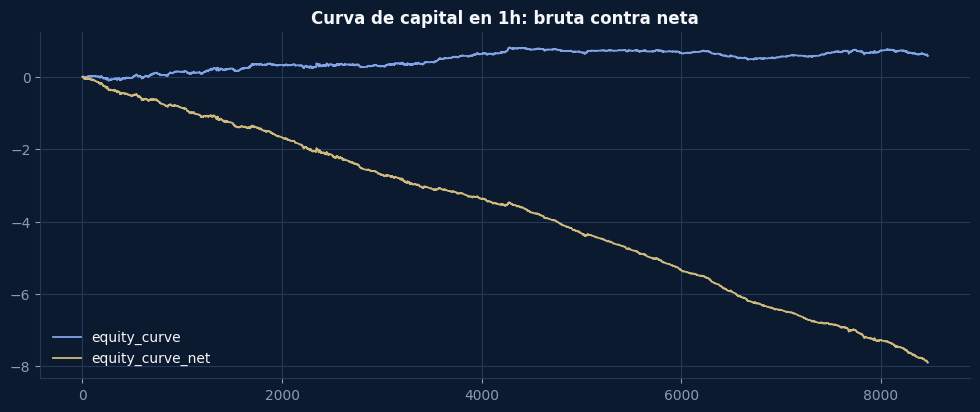

In [55]:
# Curva de capital NETA después de comisiones Taker en 1h: las comisiones destruyen la rentabilidad
research.plot_multiple_lines(model_trades, ['equity_curve', 'equity_curve_net'], 'Curva de capital en 1h: bruta contra neta')

In [56]:
# La ventaja promedio por operación frente a lo que cuesta entrar y salir
model_trades['trade_log_return'].mean(), roundtrip_fee_log

(6.860435297847214e-05, np.float64(-0.0010005003335835344))

In [57]:
# Función auxiliar en research.py que añade las curvas netas tanto para ejecución Maker como Taker
model_trades = research.add_tx_fees_log(model_trades, maker_fee, taker_fee)
model_trades

y_pred,y_true,is_won,position,trade_log_return,equity_curve,drawdown_log_return,tx_fee_log,trade_log_return_net,equity_curve_net,trade_log_return_net_maker,trade_log_return_net_taker,equity_curve_net_maker,equity_curve_net_taker
f64,f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
0.000081,0.001614,true,1.0,0.001614,0.001614,0.0,-0.001001,0.000614,0.000614,0.001214,0.000614,0.001214,0.000614
0.000096,0.00534,true,1.0,0.00534,0.006954,0.0,-0.001001,0.00434,0.004953,0.00494,0.00434,0.006154,0.004953
0.000156,-0.000782,false,1.0,-0.000782,0.006172,-0.000782,-0.001001,-0.001783,0.00317,-0.001183,-0.001783,0.004971,0.00317
0.000027,0.002777,true,1.0,0.002777,0.008948,0.0,-0.001001,0.001776,0.004946,0.002377,0.001776,0.007348,0.004946
-0.000044,0.000004,false,-1.0,-0.000004,0.008944,-0.000004,-0.001001,-0.001005,0.003942,-0.000404,-0.001005,0.006944,0.003942
…,…,…,…,…,…,…,…,…,…,…,…,…,…
-6.8083e-8,0.002461,false,-1.0,-0.002461,0.582094,-0.228786,-0.001001,-0.003462,-7.889143,-0.002861,-0.003462,-2.805384,-7.889143
0.000096,0.003788,true,1.0,0.003788,0.585882,-0.224998,-0.001001,0.002788,-7.886355,0.003388,0.002788,-2.801996,-7.886355
0.000104,0.000417,true,1.0,0.000417,0.586299,-0.224581,-0.001001,-0.000583,-7.886939,0.000017,-0.000583,-2.801979,-7.886939


In [58]:
# Probamos ampliar el horizonte temporal a velas de 6 horas ('6h') para capturar movimientos más amplios y pagar menos comisiones
time_interval = '6h'
annualized_rate = research.sharpe_annualization_factor(time_interval, 365, 24)
ts = research.load_ohlc_timeseries_range(sym, time_interval, start_date, end_date)
ts

datetime,open,high,low,close
datetime[μs],f64,f64,f64,f64
2022-01-01 00:00:00,46210.57,47566.66,46210.55,47184.18
2022-01-01 06:00:00,47184.19,47338.0,46700.09,46755.01
2022-01-01 12:00:00,46755.01,47943.77,46755.01,47733.16
2022-01-01 18:00:00,47733.16,47832.04,47202.47,47704.35
2022-01-02 00:00:00,47704.35,47745.61,46749.99,47077.7
…,…,…,…,…
2026-10-30 18:00:00,77152.1,77337.5,76270.0,77312.6
2026-10-31 00:00:00,77312.5,77615.1,77060.0,77232.9
2026-10-31 06:00:00,77232.8,77664.9,77200.5,77576.2


In [59]:
# Generamos el retorno objetivo y sus rezagos sobre la serie de 6h
ts = research.add_log_return_features(ts, 'close', forecast_horizon, max_no_lags=max_lags).drop_nulls()
ts

datetime,open,high,low,close,close_log_return,close_log_return_lag_1,close_log_return_lag_2,close_log_return_lag_3,close_log_return_lag_4
datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64
2022-01-02 06:00:00,47076.58,47500.0,46963.66,47231.3,0.003257,-0.013223,-0.000604,0.020705,-0.009137
2022-01-02 12:00:00,47231.29,48000.0,47002.47,47402.3,0.003614,0.003257,-0.013223,-0.000604,0.020705
2022-01-02 18:00:00,47401.6,47469.46,46605.68,47280.0,-0.002583,0.003614,0.003257,-0.013223,-0.000604
2022-01-03 00:00:00,47280.01,47288.28,46717.26,47083.37,-0.004168,-0.002583,0.003614,0.003257,-0.013223
2022-01-03 06:00:00,47083.37,47436.26,46777.0,47364.11,0.005945,-0.004168,-0.002583,0.003614,0.003257
…,…,…,…,…,…,…,…,…,…
2026-10-30 18:00:00,77152.1,77337.5,76270.0,77312.6,0.002078,-0.002509,-0.015132,0.00719,-0.036403
2026-10-31 00:00:00,77312.5,77615.1,77060.0,77232.9,-0.001031,0.002078,-0.002509,-0.015132,0.00719
2026-10-31 06:00:00,77232.8,77664.9,77200.5,77576.2,0.004435,-0.001031,0.002078,-0.002509,-0.015132


In [60]:
# Benchmark de cada rezago en 6h usando MSELoss
research.benchmark_linear_models(ts, target, feature_pool, annualized_rate, loss=nn.MSELoss())

features,target,no_trades,win_rate,avg_win,avg_loss,best_trade,worst_trade,ev,std,total_log_return,compound_return,max_drawdown,equity_trough,equity_peak,sharpe,weights,biases
str,str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str
"""close_log_return_lag_4""","""close_log_return""",1411,0.523033,0.007837,-0.007635,0.075276,-0.088826,0.000457,0.011665,0.645289,1.906538,-0.331602,-0.071237,0.69516,1.497995,"""[-0.05934]""","""0.000184"""
"""close_log_return_lag_3""","""close_log_return""",1411,0.496811,0.007848,-0.007634,0.088826,-0.075276,0.000058,0.011674,0.081214,1.084603,-0.29005,-0.27085,0.167146,0.18839,"""[0.02618]""","""0.000169"""
"""close_log_return_lag_1""","""close_log_return""",1411,0.520907,0.007462,-0.008043,0.088826,-0.063243,0.000034,0.011674,0.047977,1.049146,-0.35119,-0.254283,0.242495,0.11129,"""[-0.00167]""","""0.000174"""
"""close_log_return_lag_2""","""close_log_return""",1411,0.496811,0.007619,-0.007861,0.088826,-0.063243,-0.00017,0.011673,-0.240529,0.786212,-0.586017,-0.562507,0.023511,-0.558002,"""[0.03272]""","""0.000168"""


In [61]:
# Benchmark de cada rezago en 6h usando L1Loss (MAE)
benchmark = research.benchmark_linear_models(ts, target, feature_pool, annualized_rate, loss=nn.L1Loss())
benchmark

features,target,no_trades,win_rate,avg_win,avg_loss,best_trade,worst_trade,ev,std,total_log_return,compound_return,max_drawdown,equity_trough,equity_peak,sharpe,weights,biases
str,str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str
"""close_log_return_lag_4""","""close_log_return""",1411,0.525868,0.007819,-0.007654,0.075276,-0.088826,0.000483,0.011664,0.680875,1.975606,-0.341412,-0.071237,0.730747,1.580744,"""[-0.04829]""","""0.000142"""
"""close_log_return_lag_3""","""close_log_return""",1411,0.498228,0.007873,-0.007609,0.088826,-0.075276,0.000104,0.011674,0.147084,1.158452,-0.287107,-0.207928,0.21116,0.341198,"""[0.01562]""","""0.000107"""
"""close_log_return_lag_1""","""close_log_return""",1411,0.50815,0.007536,-0.007952,0.088826,-0.057483,-0.000082,0.011674,-0.115169,0.891216,-0.393423,-0.267618,0.125805,-0.267157,"""[-0.05183]""","""0.000145"""
"""close_log_return_lag_2""","""close_log_return""",1411,0.508859,0.007309,-0.008188,0.088826,-0.063243,-0.000302,0.01167,-0.42641,0.652848,-0.603408,-0.488278,0.11513,-0.989454,"""[0.00618]""","""0.000116"""


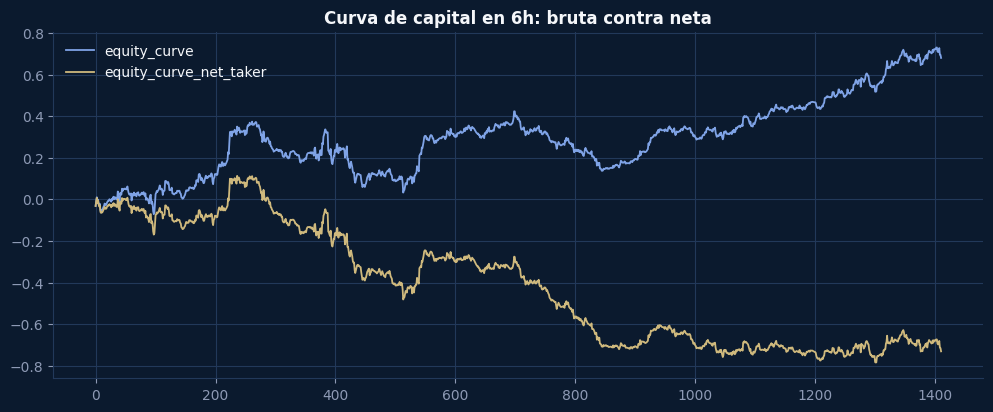

In [62]:
# Evaluamos el mejor rezago en el horizonte de 6h: curva bruta contra curva neta (Taker)
features = benchmark['features'][0].split(',')
model = LinearModel(len(features))
model.apply(research.init_weights)
model_trades = research.learn_model_trades(ts, features, target, model, loss=nn.L1Loss())
model_trades = research.add_tx_fees_log(model_trades, maker_fee, taker_fee)
research.plot_multiple_lines(model_trades, ['equity_curve', 'equity_curve_net_taker'], 'Curva de capital en 6h: bruta contra neta')

## Investigación en Horizonte de 12 Horas (`12h`)
Exploramos combinaciones de hasta 3 rezagos para encontrar el modelo con mejor relación retorno/riesgo en la validación.

In [63]:
time_interval = '12h'
annualized_rate = research.sharpe_annualization_factor(time_interval, 365, 24)
ts = research.load_ohlc_timeseries_range(sym, time_interval, start_date, end_date)
ts = research.add_log_return_features(ts, 'close', forecast_horizon, max_no_lags=max_lags).drop_nulls()
ts

datetime,open,high,low,close,close_log_return,close_log_return_lag_1,close_log_return_lag_2,close_log_return_lag_3,close_log_return_lag_4
datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64
2022-01-03 12:00:00,47364.11,47575.22,45665.4,46445.81,-0.019579,0.001777,0.001031,-0.009966,0.020101
2022-01-04 00:00:00,46445.8,46750.0,45931.61,46709.98,0.005672,-0.019579,0.001777,0.001031,-0.009966
2022-01-04 12:00:00,46709.97,47524.36,45445.57,45833.42,-0.018944,0.005672,-0.019579,0.001777,0.001031
2022-01-05 00:00:00,45833.41,47075.29,45710.23,46271.93,0.009522,-0.018944,0.005672,-0.019579,0.001777
2022-01-05 12:00:00,46271.93,46820.83,42270.0,43421.69,-0.063576,0.009522,-0.018944,0.005672,-0.019579
…,…,…,…,…,…,…,…,…,…
2026-10-29 12:00:00,80130.9,81953.7,77868.4,77962.6,-0.027432,-0.014593,0.000132,0.005298,0.012296
2026-10-30 00:00:00,77962.6,78776.5,76444.0,77345.9,-0.007942,-0.027432,-0.014593,0.000132,0.005298
2026-10-30 12:00:00,77345.8,78081.3,76270.0,77312.6,-0.000431,-0.007942,-0.027432,-0.014593,0.000132


In [64]:
# Benchmark de combinaciones (hasta 3 features) con MSELoss
research.benchmark_linear_models(ts, target, feature_pool, annualized_rate, max_no_features=3, loss=nn.MSELoss())

features,target,no_trades,win_rate,avg_win,avg_loss,best_trade,worst_trade,ev,std,total_log_return,compound_return,max_drawdown,equity_trough,equity_peak,sharpe,weights,biases
str,str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str
"""close_log_return_lag_2,close_log_return_lag_4""","""close_log_return""",705,0.512057,0.012096,-0.010563,0.090769,-0.074997,0.00104,0.016704,0.732871,2.081046,-0.265265,-0.022355,0.95233,1.681383,"""[-0.04034 0.01718]""","""0.000327"""
"""close_log_return_lag_2""","""close_log_return""",705,0.500709,0.011842,-0.010852,0.080449,-0.090769,0.000511,0.016729,0.360595,1.434182,-0.280214,-0.011266,0.591654,0.826078,"""[-0.04103]""","""0.000334"""
"""close_log_return_lag_2,close_log_return_lag_3,close_log_return_lag_4""","""close_log_return""",705,0.504965,0.011628,-0.011062,0.090769,-0.074997,0.000395,0.016732,0.278604,1.321284,-0.353472,-0.052605,0.588369,0.638128,"""[-0.04147 0.04888 0.01606]""","""0.000312"""
"""close_log_return_lag_3,close_log_return_lag_4""","""close_log_return""",705,0.503546,0.011654,-0.011037,0.090769,-0.074997,0.000389,0.016732,0.274,1.315215,-0.293554,-0.064518,0.482471,0.627576,"""[0.04792 0.01776]""","""0.000297"""
"""close_log_return_lag_2,close_log_return_lag_3""","""close_log_return""",705,0.497872,0.011714,-0.010985,0.080449,-0.090769,0.000316,0.016734,0.222701,1.249447,-0.340737,-0.026391,0.519731,0.510034,"""[-0.04213 0.04925]""","""0.000317"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""close_log_return_lag_1,close_log_return_lag_3""","""close_log_return""",705,0.479433,0.011508,-0.011201,0.090769,-0.074997,-0.000313,0.016734,-0.221002,0.801715,-0.493553,-0.221002,0.272551,-0.506141,"""[0.02411 0.04929]""","""0.000294"""
"""close_log_return_lag_4""","""close_log_return""",705,0.49078,0.01116,-0.011529,0.090769,-0.074997,-0.000394,0.016732,-0.277463,0.757704,-0.581247,-0.542884,0.038363,-0.635512,"""[0.01882]""","""0.000313"""
"""close_log_return_lag_1""","""close_log_return""",705,0.48227,0.010935,-0.011732,0.090769,-0.074997,-0.000801,0.016718,-0.564364,0.568722,-0.835718,-0.705553,0.130166,-1.293766,"""[0.02211]""","""0.000312"""


In [65]:
# Benchmark de combinaciones (hasta 3 features) con L1Loss
benchmark = research.benchmark_linear_models(ts, target, feature_pool, annualized_rate, max_no_features=3, loss=nn.L1Loss())
benchmark

features,target,no_trades,win_rate,avg_win,avg_loss,best_trade,worst_trade,ev,std,total_log_return,compound_return,max_drawdown,equity_trough,equity_peak,sharpe,weights,biases
str,str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str
"""close_log_return_lag_1,close_log_return_lag_3,close_log_return_lag_4""","""close_log_return""",705,0.524823,0.011927,-0.010708,0.090769,-0.074997,0.001172,0.016696,0.825932,2.284007,-0.270243,-0.026391,1.042026,1.89588,"""[-0.0071 0.01568 -0.00088]""","""0.00028"""
"""close_log_return_lag_1,close_log_return_lag_3""","""close_log_return""",705,0.524823,0.011909,-0.010728,0.090769,-0.074997,0.001152,0.016697,0.812152,2.25275,-0.270243,-0.026391,1.028246,1.864097,"""[-0.007 0.01524]""","""0.000278"""
"""close_log_return_lag_3""","""close_log_return""",705,0.519149,0.011745,-0.010919,0.090769,-0.074997,0.000847,0.016715,0.597309,1.817223,-0.324837,-0.026391,0.821502,1.369481,"""[0.01499]""","""0.000276"""
"""close_log_return_lag_1""","""close_log_return""",705,0.514894,0.011714,-0.010959,0.090769,-0.074997,0.000715,0.016722,0.504154,1.655585,-0.24286,-0.011266,0.653126,1.155473,"""[-0.00541]""","""0.000148"""
"""close_log_return_lag_1,close_log_return_lag_4""","""close_log_return""",705,0.514894,0.011601,-0.011079,0.090769,-0.074997,0.000598,0.016726,0.421895,1.524849,-0.216483,-0.011266,0.613475,0.966677,"""[-0.00514 -0.00273]""","""0.000166"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""close_log_return_lag_2""","""close_log_return""",705,0.506383,0.011682,-0.011005,0.080449,-0.090769,0.000483,0.01673,0.340718,1.405956,-0.302428,-0.011266,0.591119,0.780503,"""[-0.04919]""","""0.000236"""
"""close_log_return_lag_1,close_log_return_lag_2,close_log_return_lag_4""","""close_log_return""",705,0.512057,0.011537,-0.011149,0.080449,-0.090769,0.000468,0.01673,0.329733,1.390597,-0.276115,-0.011266,0.560042,0.75532,"""[-0.00525 -0.05007 0.0015 ]""","""0.000258"""
"""close_log_return_lag_1,close_log_return_lag_2,close_log_return_lag_3""","""close_log_return""",705,0.506383,0.011562,-0.011128,0.080449,-0.090769,0.000362,0.016733,0.255385,1.290958,-0.36285,-0.011266,0.618235,0.584919,"""[-0.00679 -0.05226 0.008 ]""","""0.000253"""


In [66]:
# Los dos primeros modelos son casi el mismo: el peso de lag_4 es prácticamente cero
benchmark.select('features', 'ev', 'sharpe', 'max_drawdown', 'weights', 'biases').head(3)

features,ev,sharpe,max_drawdown,weights,biases
str,f64,f64,f64,str,str
"""close_log_return_lag_1,close_log_return_lag_3,close_log_return_lag_4""",0.001172,1.89588,-0.270243,"""[-0.0071 0.01568 -0.00088]""","""0.00028"""
"""close_log_return_lag_1,close_log_return_lag_3""",0.001152,1.864097,-0.270243,"""[-0.007 0.01524]""","""0.000278"""
"""close_log_return_lag_3""",0.000847,1.369481,-0.324837,"""[0.01499]""","""0.000276"""


### Guardado del Mejor Modelo (`lag_1` y `lag_3` con `L1Loss`)
Entre dos modelos que rinden casi igual, nos quedamos con el más simple (*principio de parsimonia*). Entrenamos el modelo con `lag_1` y `lag_3` y exportamos sus pesos a `model_weights.pth` para utilizarlos en el diseño de la estrategia (Notebook 2) y en el sistema de ejecución (Notebook 3).

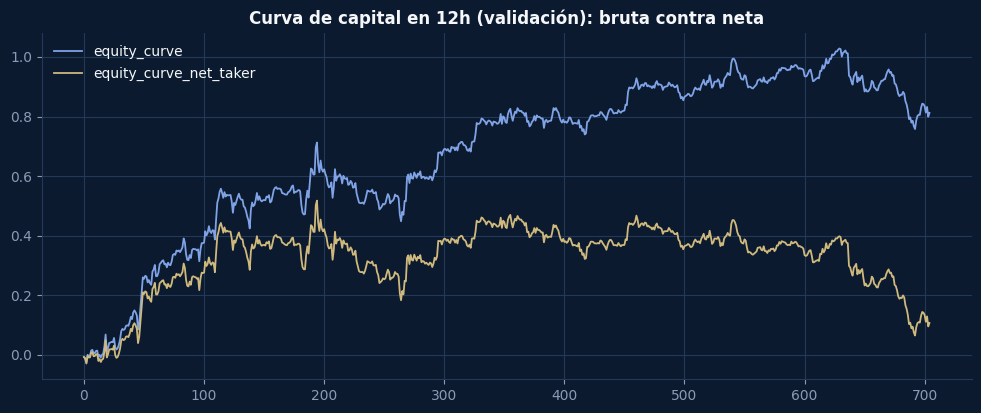

In [67]:
features = ['close_log_return_lag_1', 'close_log_return_lag_3']
model = LinearModel(len(features))
model.apply(research.init_weights)
model_trades = research.learn_model_trades(ts, features, target, model, loss=nn.L1Loss())
model_trades = research.add_tx_fees_log(model_trades, maker_fee, taker_fee)
research.plot_multiple_lines(model_trades, ['equity_curve', 'equity_curve_net_taker'], 'Curva de capital en 12h (validación): bruta contra neta')

In [68]:
# Parámetros aprendidos: el sesgo y un peso por cada rezago
research.print_model_params(model)

linear.weight:
[[-0.00699938  0.01524278]]
linear.bias:
[0.0002775]


In [69]:
# Guardamos el diccionario de pesos (state_dict) del modelo entrenado en disco
torch.save(model.state_dict(), 'model_weights.pth')

In [70]:
# Guardamos también las velas de 12h: son la entrada de los notebooks 2 y 3
load_cols = ['datetime', 'open', 'high', 'low', 'close']
research.load_ohlc_timeseries_range(sym, time_interval, start_date, end_date).select(load_cols).write_csv(f'{sym}_{time_interval}_ohlc.csv')

In [71]:
# fin del notebook 1: tenemos los datos (C) y un modelo con una ventaja pequeña antes de comisiones (A)
# en el notebook 2 abrimos por primera vez el tramo de prueba y construimos la estrategia: Simulación, Tamaño y Libre de sesgos